##### Master Degree in Computer Science and Data Science for Economics and Health

# The residual stream and the Transformer block

### Prof. Alfio Ferrara

## Introduction

In L1.0 we built a network with one ingredient, **attention**, and we saw that a second layer lets the network solve a problem that one layer cannot. The model had a very simple form. For a list of words $w_1, \dots, w_T$:

$$
x_t^{(0)} = E[w_t] + P[t], \qquad x^{(l)} = x^{(l-1)} + \mathrm{Attn}_l\big(x^{(l-1)}\big) \quad (l = 1, \dots, L), \qquad \text{scores}_t = x_t^{(L)}\, W_U + b,
$$

where $E$ is the table of the word embeddings, $P$ the table of the position embeddings, $\mathrm{Attn}_l$ the attention of layer $l$ (one head), and $W_U$, $b$ the output layer, that turns a vector into one score for each word. A real Transformer is the same scheme with three more ingredients, and this notebook introduces them one at a time:

1. **the residual stream**: the vector $x$ that goes through the layers, that each component reads and adds to. We already used it in L1.0 without looking at it; here we look at it and we say what we get from it (Step 1);
2. **multiple heads**: several attentions in parallel inside the same layer (Step 2);
3. **the MLP**: a computation that works on each position on its own, after the attention (Step 3);
4. **layer normalization**: a rescaling of the vectors, that keeps the training under control (Step 4).

In Step 5 we put them together in the **Transformer block**, the piece that a Transformer repeats. For each ingredient we follow the same order: we say **what we want to obtain** and what it brings to the network, we write **how the formula above changes**, and we look at **what it does to the data** of our toy world.

A note on what to expect. The toy world is small, and for some of these ingredients we will not see a large increase of the accuracy: a network with a few thousand parameters solves our problems also without them. When this happens we say it, and we show with other data (a different task, a smaller network) **what would change**. The point of the notebook is to understand what each piece does, more than to measure how much better the network becomes. As in L1.0, we use few seeds (two or three) to keep the execution short, and we say how many in each case: the results are an indication, not a measure.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from nlp import toyworld, tinylm

warnings.filterwarnings("ignore", category=FutureWarning)

We use the same world and the same lists as in L1.0: twelve people, six drinks, and lists of three people to be read (`marco juice mario water chiara coffee . mario drinks` → `water`). The training set has 20,000 lists and the test set 2,000 new ones. The list is `<s> n1 d1 n2 d2 n3 d3 . asked drinks answer </s>`, and the answer is predicted from the position of `drinks`.

In [2]:
world = toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=0))
vocabulary = world.vocabulary()

train = torch.tensor(vocabulary.batch(world.recall(10, 20000, items=3)))               # 20,000 lists of 3 people
test = torch.tensor(vocabulary.batch(world.recall(11, 2000, items=3)))
print(" ".join(vocabulary.decode(test[0].tolist())))

DRINK_IDS = torch.tensor([vocabulary.index[d] for d in world.values["drink"]])
STEPS = 12000
trained = {}

def train_models(name, seeds, **kwargs):
    for seed in seeds:
        start = time.time()
        model = tinylm.fit_recall(train, seed=seed, steps=STEPS, **kwargs)
        trained[name, seed] = model
        print(f"{name}, seed {seed}: {model.n_parameters():,} parameters, accuracy {tinylm.answer_accuracy(model, test):.1%}, "
              f"final loss {model.loss_curve[-1]:.2f}, {time.time() - start:.0f} s")

<s> marco juice mario water chiara coffee . mario drinks water </s>


## Step 1: the residual stream

> **A simple example.** Take the list `marco juice mario water chiara coffee . mario drinks`. At the end of the network the vector of the position of `drinks` has to say `water`. The word `drinks` alone knows nothing about the drink of `mario`, so the answer is not in the vector at the beginning: something has to **write** it there. Think of the vector as a page on which each stage of the network writes a note, without erasing the notes of the others: the first stage can write *this position is asking about `mario`*, the second can write *the drink of `mario` is `water`*. At the end we read the whole page.
>
> The question of this section is: if the vector is a page where every stage adds its note, can we **separate the notes** and see what each stage wrote, and how much each note counts for the answer? The intuition is that if the final vector is a *sum*, and the output layer is *linear*, then the scores of the answer are also a sum, with one term for each stage.

### What we want to obtain

In L1.0 each layer did $x \leftarrow x + \mathrm{Attn}(x)$: the output of the layer is **added** to its input, and it does not replace it. This is the **residual connection** (He et al., 2016, for deep networks of images). We wanted two things from it, and now we can say them better.

- **Nothing that was known is lost.** The vector of a position starts with its word and its place. After the layer it still contains them, plus what the layer has read from the other positions. Without the sum, a layer that wants to pass the word to the next one has to *learn to copy it*; with the sum the copy is free, and the layer has only to say what is **new**.
- **The layers talk to each other through a common space.** All the components read from the same vector and write into the same vector, so what a layer writes is what the following layers can read. In L1.0 this is exactly how the second layer used what the first had brought: the names. For this reason the vector is called the **residual stream**: a channel of dimension $d$ that goes through the whole network, and that every component reads and adds to.

### The formula, unrolled

If we apply $x^{(l)} = x^{(l-1)} + f_l\big(x^{(l-1)}\big)$ for all the layers and we replace each $x^{(l-1)}$ with its definition, we get that the final vector is a **sum**:

$$
x^{(L)} = x^{(0)} + f_1\big(x^{(0)}\big) + f_2\big(x^{(1)}\big) + \dots + f_L\big(x^{(L-1)}\big) = x^{(0)} + \sum_{l=1}^{L} f_l\big(x^{(l-1)}\big).
$$

The first term is the embedding of the word plus that of the place; each of the others is **what one component wrote**. Since the output layer is linear, $\text{scores} = x^{(L)} W_U + b$, the scores are a sum too:

$$
\text{scores} = x^{(0)} W_U \;+\; \sum_{l=1}^{L} f_l\big(x^{(l-1)}\big) W_U \;+\; b.
$$

Each term $f_l\,W_U$ says **how much that component pushes each word** towards the answer or away from it. This is called the *direct logit attribution*, and it is an exact decomposition of the scores of our network (which has no normalization yet: in Step 4 we will see what changes when it has one). It counts the **direct** effect only: what a layer writes and that the output layer reads as it is. What a layer writes to be read by the following layers (as the names of the first layer, in our problem) is not a direct effect, and the decomposition does not count it.

The model of L1.0 has a method `stream` that returns the terms of the sum for each position. First a check that the sum of the terms is the vector that the output layer reads, and that its scores are those of the network. We use the networks of L1.0 (two layers of attention, three seeds), that we train again here with the same settings.

In [3]:
train_models("two layers", range(3), layers=2)

two layers, seed 0: 12,596 parameters, accuracy 100.0%, final loss 0.00, 23 s
two layers, seed 1: 12,596 parameters, accuracy 100.0%, final loss 0.00, 23 s
two layers, seed 2: 12,596 parameters, accuracy 100.0%, final loss 0.00, 23 s


In [4]:
model = trained["two layers", 1]
terms = model.stream(test[:1, :-2])                                      # the list without the answer
print("position of `drinks`; the terms of the sum:")
for name, term in terms:
    print(f"  {name:22s} vector of {term.shape[-1]} numbers, length {term[0, -1].norm():.2f}")
total = sum(term for _, term in terms)
scores = model.unembed(total)
print("the sum of the terms gives the scores of the network:", torch.allclose(scores, model(test[:1, :-2]), atol=1e-5))

position of `drinks`; the terms of the sum:
  embedding + position   vector of 32 numbers, length 5.40
  attention of layer 1   vector of 32 numbers, length 5.01
  attention of layer 2   vector of 32 numbers, length 15.55
the sum of the terms gives the scores of the network: True


Now the decomposition on the 2,000 test lists. For each term we measure two things on the position of `drinks`, the one that predicts the answer:

- **the direct contribution to the answer**: the score that the term gives to the right drink minus the mean of the scores that it gives to the other five drinks ($f_l W_U$ restricted to the six drinks; for the first term the embedding of the position of `drinks`, that is the same in all the lists and cannot know the answer);
- **the partial sum**: if we stopped after this term and we asked the output layer which word wins, how often is it the right one? It is the accuracy of $\left(x^{(0)} + \dots + f_l\right) W_U + b$.

In [5]:
def residual_decomposition(model, sequences):
    terms = model.stream(sequences[:, :-2])
    W, b = model.unembed.weight, model.unembed.bias
    answer = sequences[:, -2]
    right = DRINK_IDS[None] == answer[:, None]
    partial, rows = 0, []
    for name, term in terms:
        h = term[:, -1]                                                  # the position of `drinks`
        direct = (h @ W.T)[:, DRINK_IDS]                                 # what the term gives to each of the six drinks
        margin = (direct * right).sum(1) - (direct * ~right).sum(1) / (len(DRINK_IDS) - 1)
        partial = partial + h
        accuracy = ((partial @ W.T + b).argmax(-1) == answer).float().mean().item()
        rows.append({"term": name, "length of the vector": h.norm(dim=-1).mean().item(),
                     "direct contribution to the answer": margin.mean().item(), "accuracy of the partial sum": accuracy})
    return pd.DataFrame(rows).set_index("term")

pd.concat({f"seed {seed}": residual_decomposition(trained["two layers", seed], test) for seed in range(3)}).round(2)

length of the vector  \
       term                                         
seed 0 embedding + position                  6.71   
       attention of layer 1                 14.20   
       attention of layer 2                 21.56   
seed 1 embedding + position                  5.40   
       attention of layer 1                  6.80   
       attention of layer 2                 17.06   
seed 2 embedding + position                  4.69   
       attention of layer 1                  8.94   
       attention of layer 2                 13.20   

                             direct contribution to the answer  \
       term                                                      
seed 0 embedding + position                              -0.03   
       attention of layer 1                               4.31   
       attention of layer 2                              16.78   
seed 1 embedding + position                              -0.00   
       attention of layer 1                               0.02   
       attention of layer 2                              14.43   
seed 2 embedding + position                               0.00   
       attention of layer 1                               0.39   
       attention of layer 2                              11.73   

                             accuracy of the partial sum  
       term                                               
seed 0 embedding + position                         0.16  
       attention of layer 1                         0.46  
       attention of layer 2                         1.00  
seed 1 embedding + position                         0.16  
       attention of layer 1                         0.16  
       attention of layer 2                         1.00  
seed 2 embedding + position                         0.16  
       attention of layer 1                         0.18  
       attention of layer 2                         1.00

In [6]:
rows = {}
for seed in range(3):
    model = trained["two layers", seed]
    row = {"all the terms": tinylm.answer_accuracy(model, test)}
    for k in range(2):
        model.layers[k].identity = True                                  # the layer writes nothing new: each position reads only itself
        row[f"attention of layer {k + 1} removed"] = tinylm.answer_accuracy(model, test)
        model.layers[k].identity = False
    rows[f"seed {seed}"] = row
pd.DataFrame(rows).T.round(2)

,all the terms,attention of layer 1 removed,attention of layer 2 removed
seed 0,1.0,0.16,0.46
seed 1,1.0,0.35,0.19
seed 2,1.0,0.16,0.20


The table separates the two layers in a way that matches what we read in the maps of L1.0. For **seeds 1 and 2** the embedding and the position contribute nothing to the answer (−0.00 and 0.00: the vector of `drinks` is the same in all the lists, it cannot know which drink is the right one), and the same is true, almost, for the **first layer** (0.02 and 0.39 against 14.43 and 11.73 of the second). The partial sum after the first layer is as bad as the one after the embedding (16% and 18%, with six drinks the chance is 16.7%), and the **second layer** brings it to 100%. So the first layer writes in the stream something that the output layer cannot use to answer, and the second layer, reading it, writes the answer. The names that the first layer brings to the positions are *notes for the following layer*, not part of the answer, and this is why the direct contribution does not see them. The last table shows that they count anyway: without the attention of the first layer the accuracy falls to 35% and 16%, without that of the second layer to 19% and 20% (they are the numbers of L1.0). The decomposition tells **who wrote the answer**; the ablation tells **who was needed to write it**, and the two questions have different answers for the first layer.

The seed 0 confirms what we found in L1.0: it is a **different solution**. Its first layer already writes part of the answer (a direct contribution of 4.31 and a partial sum that is right 46% of the times), and the second completes it (16.78). Also here the decomposition is a piece of evidence and not an explanation: it says where in the stream the answer appears, and it does not say how the layer computes it.

**What changes with the real models.** The decomposition works in the same way when the terms are tens of layers, each with many heads and an MLP (the terms of the sum are then the contributions of every head and of every MLP), and it is one of the tools with which these models are studied (*A Mathematical Framework for Transformer Circuits*, Elhage et al., 2021, presents the residual stream as the central object of the architecture). It becomes only approximate when the model normalizes the vectors before the output layer, as all the real ones do (Step 4). And the size of the stream, $d$, is a **bandwidth** shared by everything that the model wants to pass between its parts: here it is 32, in the real models from hundreds to many thousands.

So far the stream has received one note from each layer, written by **one attention** that reads one thing at a time: in L1.0 the same layer had to move the previous word *and* to look for the drink, and it did it in two different layers. Can a layer read several things at once? This is the next step.

## Step 2: several heads in the same layer

> **A simple example.** Take two very short texts of our world, `tea tea same` and `tea milk same`, and the question that the word `same` asks: *are the two drinks the same?* The answer is `yes` in the first and `no` in the second. To answer, the position of `same` has to read the first drink and the second drink **as two different things**, and compare them. An attention computes one set of weights over the words on its left and takes **one** weighted average of their values: the two drinks end up mixed in a single vector, and the network has to tell from the mixture whether they were equal.
>
> The question of this section is: can a layer look at the same text in **several ways at once**, so that each way takes something different? The intuition is to give the layer several small attentions side by side, each with its own weights, and let each of them write its own note in the stream.

### What we want to obtain

In L1.0 a layer had **one** attention: for each position, one distribution of weights and one average. When the network needed two different readings (to bring the previous word, and to look for the drink) it used two layers, one after the other. But two readings that do **not depend on each other** do not need to wait for each other: they can be done at the same time, on the same input, in the same layer. The layers remain for what is **sequential**, for example reading what another layer has written. A layer with several heads does what one layer of L1.0 did, many times in parallel, each time with different weights, so it can follow different patterns (the previous word, the first word of the list, the word with the same content...).

### The formula

With $H$ heads, the vector of dimension $d$ is split into $H$ parts of dimension $d_h = d / H$. Each head $h$ has its own matrices $W_Q^{(h)}, W_K^{(h)}, W_V^{(h)} \in \mathbb{R}^{d \times d_h}$ and computes the attention of L1.0 in its small space:

$$
\mathrm{head}_h = \mathrm{softmax}\!\left(\frac{(x W_Q^{(h)})(x W_K^{(h)})^\top}{\sqrt{d_h}} + \text{mask}\right) x W_V^{(h)},
$$

and the layer concatenates the results and mixes them with the output matrix $W_O$ ($d \times d$):

$$
\mathrm{Attn}(x) = \big[\mathrm{head}_1 ; \dots ; \mathrm{head}_H\big]\, W_O = \sum_{h=1}^{H} \mathrm{head}_h\, W_O^{(h)},
$$

where $W_O^{(h)}$ is the block of $d_h$ rows of $W_O$ that reads the head $h$. The second form connects this step to the previous one: **every head writes its own term in the residual stream**, so the sum of Step 1 now has one term for each head. Note also that the number of parameters does **not** depend on $H$: the matrices $W_Q, W_K, W_V$ of all the heads together are three matrices $d \times d$, whatever the number of heads, and $W_O$ is one more. More heads do not cost more parameters; they cost **smaller spaces**: each head compares and copies vectors of dimension $d_h$, and with $d = 32$ and 8 heads this is 4. In the real models the heads have dimension 64 to 128 (GPT-2 small has 12 heads of dimension 64, $d = 768$).

### The data: are the two drinks the same?

The world generates this kind of text with `comparison`: two drinks, the word `same`, and the answer `yes` or `no` (the two drinks are equal in half of the texts by construction, plus the times in which two random drinks coincide). The network reads `<s> x y same` and has to say the answer from the position of `same`. We use the same training as before, on one layer, to look at what a layer with several heads can do **alone**.

In [7]:
vocabulary_cmp = world.vocabulary(extra=toyworld.COMPARISON_WORDS)
train_cmp = torch.tensor(vocabulary_cmp.batch(world.comparison(1, 20000)))
test_cmp = torch.tensor(vocabulary_cmp.batch(world.comparison(2, 2000)))
for sentence in world.comparison(0, 4):
    print(" ".join(sentence))
print(f"\nthe most frequent answer (`yes`) is right in {(test_cmp[:, -2] == vocabulary_cmp.index['yes']).float().mean():.1%} of the test texts")

<s> cocoa cocoa same yes </s>
<s> juice juice same yes </s>
<s> coffee coffee same yes </s>
<s> juice cocoa same no </s>

the most frequent answer (`yes`) is right in 58.5% of the test texts


We train a layer of attention with 1, 2, 4 and 8 heads, with the same dimension $d = 32$ and so **the same number of parameters**, for 8,000 steps and three seeds. The reference is the most frequent answer, that a network that does not compare the two drinks can always give.

In [8]:
STEPS_CMP = 8000
trained_cmp = {}
rows = {}
for heads in (1, 2, 4, 8):
    start = time.time()
    for seed in range(3):
        model = tinylm.fit_recall(train_cmp, seed=seed, steps=STEPS_CMP, layers=1, heads=heads)
        trained_cmp[heads, seed] = model
        rows.setdefault(f"{heads} head" + ("s" if heads > 1 else ""), {})[f"seed {seed}"] = tinylm.answer_accuracy(model, test_cmp)
    print(f"{heads} heads: {model.n_parameters():,} parameters, {(time.time() - start) / 3:.0f} s for each network")
for seed in range(3):                                                    # for comparison: two layers of one head each
    model = tinylm.fit_recall(train_cmp, seed=seed, steps=STEPS_CMP, layers=2, heads=1)
    rows.setdefault("2 layers, 1 head each", {})[f"seed {seed}"] = tinylm.answer_accuracy(model, test_cmp)
print(f"2 layers of 1 head: {model.n_parameters():,} parameters")
pd.DataFrame(rows).T.round(2)

1 heads: 8,760 parameters, 5 s for each network
2 heads: 8,760 parameters, 5 s for each network
4 heads: 8,760 parameters, 5 s for each network
8 heads: 8,760 parameters, 6 s for each network
2 layers of 1 head: 12,856 parameters


,seed 0,seed 1,seed 2
1 head,0.78,0.71,0.65
2 heads,1.00,1.00,0.73
4 heads,1.00,1.00,1.00
8 heads,1.00,1.00,1.00
"2 layers, 1 head each",1.00,1.00,1.00


With the same number of parameters (8,760) the number of heads changes the result a lot. A layer with **one head** stays between 65% and 78%, not far from the 58.5% of the reference that does not compare, and it does not solve the problem in any of the three seeds; with **two heads** two seeds out of three reach 100% and the third 73%; with **four** and **eight heads** all the seeds reach 100%. The last row is the same problem with two layers of one head each: it reaches 100% in the three seeds, with 12,856 parameters: two layers can do what several heads do, at a higher cost in parameters, since the second layer has its own matrices, while the heads share the same ones. A trial outside the notebook, with five seeds, a slightly different code and the same 8,000 steps, gives the same order (one head 58% to 77%, two heads 80% to 100%, four heads 97.5% to 100%, eight heads 100%). We did not prove that a layer with one head *cannot* solve this problem, but that this training does not find the solution, and that more heads find it more easily, at the same cost in parameters.

Why do the heads help? The first guess is that each head reads one of the two drinks and the layer compares what they bring. We can look at it. The figure shows, for a network with one head and for one with four (seed 0), what **each head** does: the weight that the position of `same` gives to the first drink, for each of the 36 pairs of drinks (rows: the first drink $x$, columns: the second drink $y$). Above each map, the accuracy of the network when that head is **silenced**, that is when its term is taken away from the sum of the stream (Step 1).

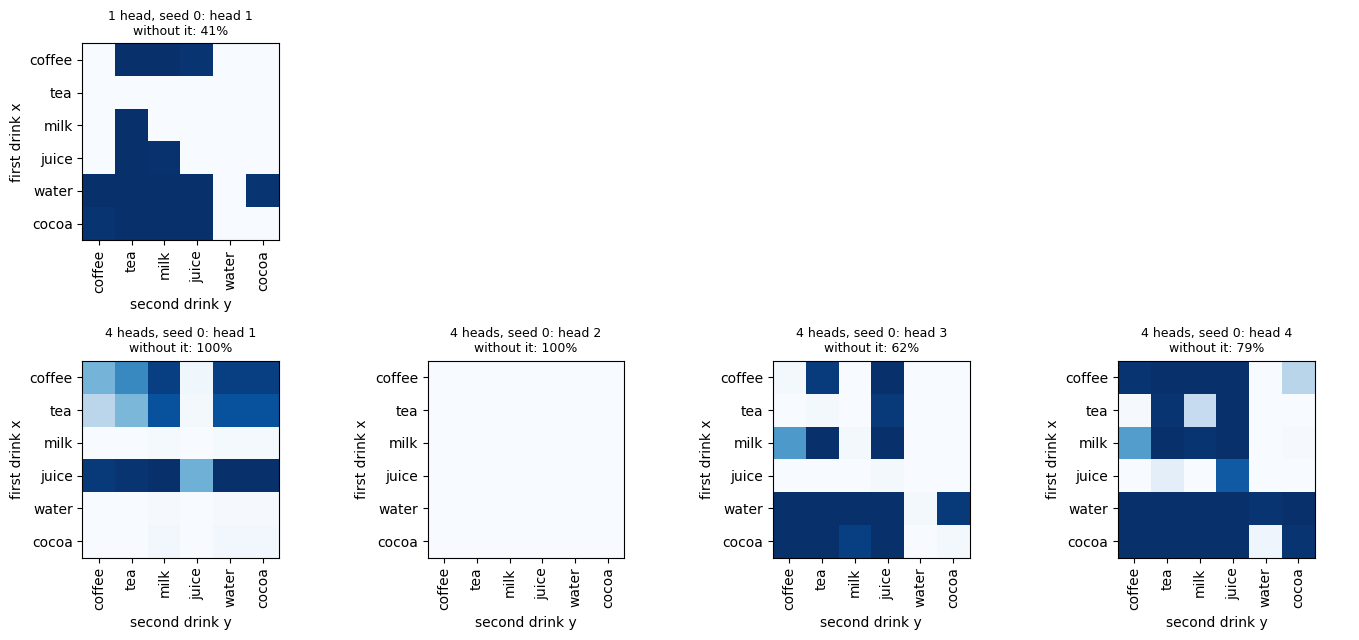

In [9]:
def attention_on_first_drink(model, head):
    # weight that the head gives, from the position of `same`, to the first drink x, for every pair (x, y) of drinks
    drinks = world.values["drink"]
    pairs = torch.tensor([[vocabulary_cmp.index["<s>"], vocabulary_cmp.index[x], vocabulary_cmp.index[y], vocabulary_cmp.index["same"]]
                          for x in drinks for y in drinks])
    return model.attention_maps(pairs)[0][:, head, -1, 1].reshape(len(drinks), len(drinks)).numpy()

def accuracy_without_head(model, head):
    model.layers[0].silenced = [head]
    accuracy = tinylm.answer_accuracy(model, test_cmp)
    model.layers[0].silenced = []
    return accuracy

drinks = world.values["drink"]
chosen = [(1, 0), (4, 0)]                                                # (heads, seed)
fig, axes = plt.subplots(len(chosen), 4, figsize=(14, 6.5))
for row, (heads, seed) in enumerate(chosen):
    model = trained_cmp[heads, seed]
    for h in range(4):
        ax = axes[row, h]
        if h < heads:
            im = ax.imshow(attention_on_first_drink(model, h), cmap="Blues", vmin=0, vmax=1)
            ax.set_title(f"{heads} head{'s' if heads > 1 else ''}, seed {seed}: head {h + 1}\nwithout it: {accuracy_without_head(model, h):.0%}", fontsize=9)
            ax.set_xticks(range(len(drinks)))
            ax.set_xticklabels(drinks, rotation=90)
            ax.set_yticks(range(len(drinks)))
            ax.set_yticklabels(drinks)
            ax.set_xlabel("second drink y")
            ax.set_ylabel("first drink x")
        else:
            ax.axis("off")
plt.tight_layout()

The maps do not show what we guessed. If a head simply *read the first drink* the weight would be the same in every column of a row, and it is not: the weight that a head gives to $x$ **changes with $y$** and is almost always close to 0 or to 1. The reason is in the softmax. The position of `same` is the same in all the texts, so its query is always the same; the weight on $x$ is then a competition between a score that depends on $x$ and a score that depends on $y$ (and on the other positions), and so the weight on the first drink is a function of **both** drinks. Each head draws its own region in the table of the 36 pairs, and no head alone draws the diagonal, that is the pairs with $x = y$: the equality comes from **combining** the notes of several heads. In the network with one head, the head is necessary (without it the accuracy falls to 41%, below the reference) and not sufficient (78% with it); in the network with four heads the heads 3 and 4 are the ones that count (without them 62% and 79%), and the head 1 and the head 2 can be taken away without any loss (100%): the head 2 gives no weight to the first drink for any pair, so it is looking elsewhere. We read this as a plausible description, not as a proof: we did not follow where the heads put their attention, nor how their notes are combined by the output layer.

So heads do not divide the work in a way that is easy to name, and some of them can be redundant (a result that is known also for the real models, where many heads can be removed with little loss). What is true in our data is the effect of having more: with more heads the training **finds** a combination that works, in more seeds. **What changes with the real models.** In a real model heads are tens in each layer, and in many cases they have been given a recognizable role: heads that look at the previous word, that follow the syntax, that copy a word seen earlier (those of the induction circuit that we mentioned in L1.0). But, as here, the roles are seen after training, they are not assigned by the architecture, and they must be checked head by head.

The heads write in the stream, and all together they can read the text in several ways. But what they write is always a **weighted average of values** of the other positions, a linear combination of what is already there. The next ingredient does something that an average cannot do.

## Step 3: the MLP

> **A simple example.** Take a list of four drinks, `milk tea tea coffee`, and the question *is the number of `tea` even?* (here two: the answer is `yes`). The attention can gather the four drinks in one vector, as an average of their values: for this list the average says *a half of the drinks are `tea`*. But the answer is not a smooth function of that fraction. With four drinks the fraction of `tea` can be 0, 1/4, 1/2, 3/4 or 1, and the answers are `yes`, `no`, `yes`, `no`, `yes`: it goes up and down. A **linear** reading of the average, that is a score that grows or decreases with the fraction, cannot give this answer.
>
> The question of this section is: once the attention has gathered what is needed in a vector, can the network **compute** something on it, a function that is not a weighted sum? The intuition is to add, after the attention, a small network that works on the vector of each position on its own, and that can draw up and down curves on what the attention has brought.

### What we want to obtain

An attention does one thing: it **moves information between positions**. What it writes in a position is a weighted average of the values of the others, a linear combination of vectors (the only non-linear part, the softmax, decides the weights). It does not compute new features on a vector. The MLP does the opposite: it looks at **one position at a time**, without reading the others, and applies to its vector a non-linear function. In the Transformer the two work together, and this is the division of labour: the attention is the **communication** between positions, the MLP is the **computation** inside a position.

There is a second reading of the MLP, that comes from L1.0. There we distinguished a world that is *known* (learned in the weights) from a list that is *read* (given in the context), and the attention reads the context. Where is the knowledge of the world? A hidden unit of the MLP is made of a *row* of the first matrix, which acts as a **key** (it is large when the vector contains a certain pattern), and a *column* of the second, which is the **value** that the unit writes in the stream when it is active. The MLP can be read as a memory with keys and values, and it is the place where the real models are believed to keep a good part of what they know (Geva et al., 2021; the interpretation is supported by evidence, but it is still discussed).

### The formula

$$
\mathrm{MLP}(x) = W_2\, \sigma\big(x W_1 + b_1\big) + b_2, \qquad W_1 \in \mathbb{R}^{d \times 4d},\; W_2 \in \mathbb{R}^{4d \times d},
$$

with $\sigma$ the GELU, a smooth version of the ReLU that we have already used (the factor 4 is the one of the original Transformer: $d = 512$ and a hidden layer of 2,048). The layer of L1.0, $x \leftarrow x + \mathrm{Attn}(x)$, becomes two steps, both added to the stream:

$$
x \leftarrow x + \mathrm{Attn}(x), \qquad x \leftarrow x + \mathrm{MLP}(x).
$$

In the sum of Step 1 each layer now has the terms of its heads and one term for its MLP. The MLP has $8d^2$ weights against the $4d^2$ of the attention: in our network it doubles the parameters of the layer, from 8,760 to 17,112 in total, and in the real models it holds about two thirds of the parameters of a block.

### The data: is the number of teas even?

The world generates this kind of list with `parity`: four drinks chosen among `tea`, `milk` and `coffee`, the question `tea even`, and the answer `yes` or `no`. We read `<s> d1 d2 d3 d4 tea even` and we answer from the position of `even`.

In [10]:
vocabulary_par = world.vocabulary(extra=toyworld.PARITY_WORDS)
train_par = torch.tensor(vocabulary_par.batch(world.parity(1, 20000)))
test_par = torch.tensor(vocabulary_par.batch(world.parity(2, 2000)))
for sentence in world.parity(0, 4):
    print(" ".join(sentence))
count_par = (test_par[:, 1:5] == vocabulary_par.index["tea"]).sum(dim=1)
print(f"\nthe most frequent answer (`yes`) is right in {(test_par[:, -2] == vocabulary_par.index['yes']).float().mean():.1%} of the test lists")
print("lists with 0, 1, 2, 3, 4 teas:", np.bincount(count_par.numpy(), minlength=5).tolist())

<s> coffee milk milk tea tea even no </s>
<s> tea tea tea tea tea even yes </s>
<s> tea coffee milk coffee tea even no </s>
<s> milk milk coffee coffee tea even yes </s>

the most frequent answer (`yes`) is right in 51.7% of the test lists
lists with 0, 1, 2, 3, 4 teas: [424, 753, 582, 213, 28]


We compare, on **one layer**, the attention alone and the attention with the MLP, with one head and with four heads (no normalization yet), for two seeds and 6,000 steps. Since the MLP adds parameters, we add two controls that do not have it: a network with four heads and a wider vector ($d = 48$, a number of parameters similar to that with the MLP), and a network with **two** layers of attention and no MLP.

In [11]:
STEPS_PAR = 6000
configs = {"4 heads": dict(heads=4, mlp=0),
           "4 heads + MLP": dict(heads=4, mlp=4),
           "1 head + MLP": dict(heads=1, mlp=4),
           "4 heads, d = 48, no MLP": dict(heads=4, mlp=0, d=48),
           "2 layers of 4 heads, no MLP": dict(heads=4, mlp=0, layers=2)}
trained_par = {}
rows = {}
for name, options in configs.items():
    losses = []
    for seed in range(2):
        model = tinylm.fit_recall(train_par, seed=seed, steps=STEPS_PAR, model_class=tinylm.TinyTransformer, norm="none", **{"layers": 1, **options})
        trained_par[name, seed] = model
        rows.setdefault(name, {"parameters": model.n_parameters()})[f"seed {seed}"] = tinylm.answer_accuracy(model, test_par)
        losses.append(model.loss_curve[-1])
    rows[name]["final loss (mean)"] = np.mean(losses)
pd.DataFrame.from_dict(rows, orient="index").round(2)

,parameters,seed 0,seed 1,final loss (mean)
4 heads,8760,0.94,0.96,0.21
4 heads + MLP,17112,1.00,1.00,0.00
1 head + MLP,17112,0.69,0.69,0.48
"4 heads, d = 48, no MLP",16184,0.99,0.74,0.26
"2 layers of 4 heads, no MLP",12856,1.00,1.00,0.00


With four heads the attention alone reaches 0.94 and 0.96 (mean final loss 0.21). Adding the MLP, both seeds reach 1.00, with a loss of 0.00. The MLP is **not enough by itself**: with one head the accuracy stays at 0.69 in both seeds (mean loss 0.48), as in Step 2 the attention with one head does not bring to the position what is needed, and the MLP can only compute on what it receives. The two ingredients work together.

Is it just a matter of parameters? The MLP doubles them (from 8,760 to 17,112). The control with the attention alone and a wider vector ($d = 48$, 16,184 parameters) gets 0.99 and 0.74, with a mean loss of 0.26: with a similar number of parameters the network with the MLP is a little better in one seed and much better in the other (two seeds are a small sample). But the last row says that the MLP is **not the only way**: two layers of four heads, with no MLP and fewer parameters (12,856), reach 1.00 in both seeds. A second attention can compute what the MLP computes here, since its weights are a non-linear function of what the first layer wrote. So, **in this toy the MLP is useful but not necessary**, and we can not say that it is a more efficient choice than a second layer. Two trials outside the notebook go in the same direction. On the documents of L1.0 (24 people, vectors of dimension 6 to 12, so that the memory of the facts is under pressure), the network with the MLP did not learn the facts better than a network of attention alone with the same number of parameters (99.9% at $d = 8$ with the MLP, 3,313 parameters, and 99.9% to 100% for the attention alone at $d = 12$, 3,545 parameters). And the recall of L1.0, with an MLP in each layer, was solved in the same way as without it (100%, three seeds; the loss falls at steps 3,300 to 5,300, against 2,100 to 6,400).

What does the MLP write in the stream? We use the decomposition of Step 1 at the position of `even`. For each term (the embedding, the attention with its four heads, the MLP) we take its direct contribution to the answer, the score of `yes` minus the score of `no`, and we average it over the lists with 0, 1, 2, 3 and 4 `tea`. If the idea of this section is right, the term of the attention should change *smoothly* with the number of teas, and the MLP should write the alternation yes, no, yes, no, yes. The first rows are the networks **without** the MLP, where the attention has to do everything by itself.

In [12]:
def parity_decomposition(model, sequences):
    # for each term written in the stream at the position of `even`, its direct contribution to (score of `yes` - score of `no`),
    # averaged over the lists with 0, 1, 2, 3, 4 teas
    yes, no = vocabulary_par.index["yes"], vocabulary_par.index["no"]
    count = (sequences[:, 1:5] == vocabulary_par.index["tea"]).sum(dim=1)
    W = model.unembed.weight
    rows = {}
    for name, term in model.stream(sequences[:, :-2]):
        direct = (term[:, -1] @ W.T)
        direct = direct[:, yes] - direct[:, no]
        rows[name] = {f"{k} teas": direct[count == k].mean().item() for k in range(5)}
    return pd.DataFrame(rows).T

pd.concat({f"{name}, seed {seed}": parity_decomposition(trained_par[name, seed], test_par)
           for name in ("4 heads", "4 heads + MLP") for seed in range(2)}).round(1)

0 teas  1 teas  2 teas  3 teas  \
4 heads, seed 0       embedding + position    -0.3    -0.3    -0.3    -0.3   
                      attention 1              8.4    -4.9     1.8     0.1   
4 heads, seed 1       embedding + position    -1.3    -1.3    -1.3    -1.3   
                      attention 1             12.2    -4.4     4.2     1.0   
4 heads + MLP, seed 0 embedding + position     0.6     0.6     0.6     0.6   
                      attention 1              2.2    -3.3    -1.2     0.9   
                      MLP 1                   11.3   -12.1    12.8   -11.9   
4 heads + MLP, seed 1 embedding + position     0.0     0.0     0.0     0.0   
                      attention 1              6.7    -4.5    -1.7    -0.8   
                      MLP 1                   10.6   -14.2    13.1    -9.3   

                                            4 teas  
4 heads, seed 0       embedding + position    -0.3  
                      attention 1             -3.0  
4 heads, seed 1       embedding + position    -1.3  
                      attention 1             -2.3  
4 heads + MLP, seed 0 embedding + position     0.6  
                      attention 1              3.5  
                      MLP 1                    6.0  
4 heads + MLP, seed 1 embedding + position     0.0  
                      attention 1              2.1  
                      MLP 1                    8.9

The embedding and the position write a constant: they do not depend on the number of teas, and so they cannot answer. In the networks with the MLP, the term of the attention has a smooth trend (seed 0: 2.2, −3.3, −1.2, 0.9, 3.5, a curve that goes down and up; at most 6.7 in absolute value in the two seeds), and the **MLP writes the alternation**: its term is positive for 0, 2 and 4 teas and negative for 1 and 3 (seed 0: 11.3, −12.1, 12.8, −11.9, 6.0; seed 1: 10.6, −14.2, 13.1, −9.3, 8.9), and it is larger than that of the attention. It is the division of labour that we described: the attention gathers, in a form that depends on the number of teas, and the MLP turns this into the parity. The networks without the MLP show the other side. Their attention has to draw the alternation alone, and it gets the sign right for 0, 1 and 2 teas (seed 0: 8.4, −4.9, 1.8) and then it fails: for 3 teas the term should be negative and it is 0.1 and 1.0, and for 4 teas it should be positive and it is −3.0 and −2.3. The lists with 3 and 4 teas are 12% of the test lists (213 and 28 out of 2,000), and it is plausible that this is where the accuracy of 0.94 to 0.99 is lost; we did not check it. As in Step 1, this is the *direct* effect on the answer, and it does not say how the attention and the MLP compute their terms.

**What the MLP brings, and with other data.** The MLP is useful when the answer is a **non-linear function of what has been gathered**: a parity, as here, a comparison of two values, the composition of two facts. It is not needed when the task is to find and copy a word, like the recall of L1.0: the problem of that notebook was in what the queries and the keys contained, not in a computation on the result. This is why with different data (a recall, a retrieval) the MLP would change little, and with data of the other kind it can make the difference, as it does here for one layer. **What changes with the real models.** The MLPs hold about two thirds of the parameters of a block, they use variants of the GELU with a gate (a choice that we do not discuss) and, as we said, they are believed to store many of the facts of the model (Geva et al., 2021). Our toy can show the computation, and cannot show the memory at the scale at which it matters.

We have now three kinds of terms in the stream: the embedding, the heads and the MLP, and each layer adds its own. Look at the lengths of the vectors in the table of Step 1 (4.7 to 6.7 for the embedding, 6.8 to 21.6 for the layers): the stream **grows** from one term to the next, and in a network with tens of layers it would grow much more. The next ingredient keeps this under control.

## Step 4: layer normalization

> **A simple example.** Take again the list `marco juice mario water chiara coffee . mario drinks`. At the entrance of the network the vector of the position of `drinks` has a length of about 5 or 6 (Step 1). After the first layer it is longer, and after the second one longer still: every component adds its note, and the notes are not small (the table of Step 1 had lengths from 6.8 to 21.6 for what a layer writes). With ten layers, or with a few more heads and MLPs, the vector would be much longer. The next component receives it as it is, and the **size** of its input changes with the depth at which it sits and with how loud the previous notes were.
>
> The question of this section is: can we make each component receive a vector of a **known size**, whatever happened before? The intuition is to rescale the vector of each position before it is used (or after each addition), so that its length is always the same, and what matters is only its direction.

### What we want to obtain

The size of the vectors is not a detail. In the attention the scores are products $q \cdot k$ between vectors that come from the stream, and if the stream is long the scores are large, the softmax becomes almost a hard choice (one weight near 1, the others near 0) and the gradients that go through it become very small or very unstable. The same is true of the MLP, whose non-linearity is sensitive to the size of its input. If every component receives a vector of a size that we know, the weights can be initialized and trained as if the network were shallow, and **we can use a larger learning rate**: a training that diverges with a large step is the typical symptom of a scale that is out of control.

### The formula

Layer normalization (Ba et al., 2016) acts on the vector of **one position** and on its $d$ components:

$$
\mathrm{LN}(x) = \gamma \odot \frac{x - \mu(x)}{\sqrt{\sigma^2(x) + \epsilon}} + \beta, \qquad \mu(x) = \frac{1}{d}\sum_{i=1}^{d} x_i, \quad \sigma^2(x) = \frac{1}{d}\sum_{i=1}^{d} (x_i - \mu(x))^2,
$$

with $\gamma, \beta \in \mathbb{R}^d$ learned ($2d$ parameters). After the normalization the vector has mean 0 and variance 1 (so a length of about $\sqrt{d}$, here $\sqrt{32} \approx 5.7$), and $\gamma$ and $\beta$ let the network choose another scale for each component if it needs it. It uses only the vector of that position: it does not depend on the other positions or on the batch (this is the difference from batch normalization), and so it behaves in the same way in training and when the model generates text. A common variant, **RMSNorm** (Zhang and Sennrich, 2019), divides by the root mean square without subtracting the mean, and it is used in many recent models.

The question is **where** to put it, and there are two arrangements, that give two different residual streams:

$$
\text{post-LN (original Transformer):}\quad x \leftarrow \mathrm{LN}\big(x + \mathrm{Attn}(x)\big), \quad x \leftarrow \mathrm{LN}\big(x + \mathrm{MLP}(x)\big)
$$

$$
\text{pre-LN (GPT-2 and most recent models):}\quad x \leftarrow x + \mathrm{Attn}\big(\mathrm{LN}(x)\big), \quad x \leftarrow x + \mathrm{MLP}\big(\mathrm{LN}(x)\big), \quad \text{scores} = \mathrm{LN}(x)\, W_U + b.
$$

In the **post-LN** the stream itself is normalized after each addition: its length is always the same, but each normalization rescales *everything* that was written before, and the identity path from the input to the output is no longer clean. In the **pre-LN** the stream is not touched: it remains the pure sum of Step 1, and each component reads a normalized *copy* of it; the price is that the length of the stream still grows with the depth, and a last normalization is needed before the output layer. The post-LN is the arrangement of Vaswani et al. (2017); the pre-LN is the one that has been shown to train more easily, without a careful warm-up of the learning rate (Xiong et al., 2020). Our class `Block` has both (`norm="pre"` or `norm="post"`), and `norm="none"` is the network that we used up to now.

A note on Step 1. The decomposition of the scores in terms keeps being exact with the pre-LN, **if we treat the final normalization as a fixed rescaling** of each position: $\mathrm{LN}$ subtracts the mean and divides by $\sigma(x)$, and both are linear in the terms once $\sigma(x)$ is fixed to the value that it has on that list. The next cell checks it on a network trained below.

### What it does to the data

We use the problem of Step 3 (the parity of the teas, with four heads and an MLP) with **two layers**, so that the stream has three points where we can measure it: the entrance, after the first block and after the second. For each arrangement (`none`, `pre`, `post`) we train for 2,500 steps with two learning rates, the usual one (3e-3) and a ten times larger one (3e-2), for two seeds. For every network we measure the accuracy, the final loss and the **length of the vector of the stream** (mean over the positions of the test lists) at the three points.

In [13]:
STEPS_NORM = 2500
trained_norm = {}
rows = {}
for norm in ("none", "pre", "post"):
    for lr in (3e-3, 3e-2):
        accuracies, losses, lengths = [], [], []
        for seed in range(2):
            model = tinylm.fit_recall(train_par, seed=seed, steps=STEPS_NORM, lr=lr, model_class=tinylm.TinyTransformer,
                                      layers=2, heads=4, mlp=4, norm=norm)
            trained_norm[norm, lr, seed] = model
            accuracies.append(tinylm.answer_accuracy(model, test_par))
            losses.append(model.loss_curve[-1])
            lengths.append(model.norms(test_par[:, :-2]))
        rows[f"{norm}, lr {lr:g}"] = {"accuracy, seed 0": accuracies[0], "accuracy, seed 1": accuracies[1], "final loss (mean)": np.mean(losses),
                                      "length at the entrance": np.mean([l[0] for l in lengths]),
                                      "length after block 1": np.mean([l[1] for l in lengths]),
                                      "length after block 2": np.mean([l[2] for l in lengths])}
pd.DataFrame.from_dict(rows, orient="index").round(2)

,"accuracy, seed 0","accuracy, seed 1",final loss (mean),length at the entrance,length after block 1,length after block 2
"none, lr 0.003",1.00,1.00,0.00,8.12,13.85,25.95
"none, lr 0.03",0.73,0.57,0.77,5.76,204.13,11384.83
"pre, lr 0.003",1.00,1.00,0.00,7.90,8.39,10.23
"pre, lr 0.03",0.97,1.00,0.02,5.95,141.10,256.93
"post, lr 0.003",1.00,1.00,0.00,8.01,5.66,7.88
"post, lr 0.03",0.69,0.52,0.61,6.29,5.19,3.96


At the usual learning rate all the three arrangements solve the problem (1.00 in both seeds), and the lengths show how they differ. **Without normalization** the stream grows: 8.1 at the entrance, 13.9 after the first block, 26.0 after the second, more than three times in two blocks. **With the pre-LN** it grows much less (7.9, 8.4, 10.2) because every component reads a normalized copy, and so the size of what it writes does not depend on how large the stream is. **With the post-LN** the stream is rescaled after each addition and stays between 5.7 and 8.0 ($\sqrt{32} \approx 5.7$ is the length that the normalization gives, and $\gamma$ is free to change it). At this learning rate the normalization does not improve the accuracy, as we said at the beginning: the toy problem is small and a network without it solves it without trouble.

With a learning rate **ten times larger** the picture changes. The network without normalization reaches 0.73 and 0.57 (mean final loss 0.77), and its stream grows to 204 after the first block and to 11,385 after the second: the scale is out of control. The network with the **pre-LN** is the only one that learns in both seeds (0.97 and 1.00, mean loss 0.02). Its stream also grows (141 and 257), because in the pre-LN nobody normalizes it, but each component and the output layer read a normalized copy and so they are not affected. The network with the **post-LN** has a stream under control (5.2 and 4.0) and still does not learn (0.69 and 0.52, a loss of 0.61 near the 0.69 of a coin toss): keeping the length fixed is not sufficient to make a larger step work. We read these results with care: two seeds, two learning rates and 2,500 steps. A trial outside the notebook, with four learning rates (3e-3, 1e-2, 3e-2 and 1e-1) on the same problem, agrees: the pre-LN is the best at 3e-2, none of the arrangements is reliable at 1e-1, and what changes is *how* they fail: without normalization one of the seeds reaches a loss of the order of $10^5$ (the scores explode), while with a normalization before the output layer the loss never exceeds 0.69, the level of the chance. This is also what the literature reports for the pre-LN (Xiong et al., 2020), and it is the reason why we use it in the block of the next step.

The check of the decomposition on a network with the pre-LN (the one trained with the usual learning rate, seed 0): the scores are rebuilt from the terms of the stream with the final normalization seen as a rescaling.

In [14]:
model = trained_norm["pre", 3e-3, 0]
tokens = test_par[:, :-2]
with torch.no_grad():
    terms = model.stream(tokens)
    stream = sum(term for _, term in terms)                              # the pre-LN stream is the plain sum of the terms
    sigma = (stream.var(dim=-1, unbiased=False, keepdim=True) + model.final.eps).sqrt()   # the scale that the last LN gives to each position
    rescaled = sum(model.final.weight * (term - term.mean(dim=-1, keepdim=True)) / sigma for _, term in terms)
    rebuilt = rescaled @ model.unembed.weight.T + model.final.bias @ model.unembed.weight.T + model.unembed.bias
print("the scores rebuilt from the terms are those of the network:", torch.allclose(rebuilt, model(tokens), atol=1e-4))

the scores rebuilt from the terms are those of the network: True


The check is passed: the scores of the network are the sum of the contributions of the terms, once the final normalization is read as a rescaling of each position. The decomposition of Step 1 therefore remains valid for a network with the pre-LN, which is the one we use. With the post-LN there is no such sum, because the stream is normalized after every addition and a note written by the first layer is rescaled by all the normalizations that follow; this is one reason why the pre-LN is also simpler to study.

**What changes with the real models.** In a network of tens of layers the growth of the stream that we see in the first column of the table is multiplied, and the normalization is not optional: without it the training of a deep Transformer is very difficult to keep stable. The real models normalize before every attention and every MLP and before the output (pre-LN, in most cases the RMSNorm variant), and they complete the choice with a learning rate that starts small and grows in the first steps (the *warm-up*, that our training does with the schedule of L1.0 in a much simpler form). We chose the pre-LN here, and the post-LN remains the arrangement of the original paper.

We have all the ingredients: the stream, several heads, the MLP and the normalization. In the next step we put them together in the Transformer block.

## Step 5: the Transformer block

> **A simple example.** Follow the position of `drinks` in `marco juice mario water chiara coffee . mario drinks` through **one block**. The vector comes in. It is normalized, a copy is given to the heads, and each head reads the other positions in its own way and writes a note in the stream (the names, the drinks). Then the vector is normalized again, a copy goes to the MLP, which computes on what the heads have brought and writes another note. The vector goes out, longer by those notes, and enters the next block, which does the same. At the end it is normalized and the output layer turns it into the scores of the words. Nothing in this path is new: every step is one of the previous four.
>
> The question of this section is: put together, do the four ingredients make a network that solves the problem of L1.0, and **what do they change** with respect to the network with the attention alone? The intuition is that, since we already saw that two layers of attention are enough there, the complete block will not be better in accuracy, and that what could change is **how** the network learns and **what it learns**.

### The formula of the model

A block is made of two steps that read a normalized copy of the stream and add their note to it, and the model is a stack of $L$ blocks between the embedding and the output. For the list $w_1, \dots, w_T$ (compare it with the formula of the introduction):

$$
x_t^{(0)} = E[w_t] + P[t], \qquad
\begin{aligned}
x' &= x^{(l-1)} + \sum_{h=1}^{H} \mathrm{head}_h\big(\mathrm{LN}(x^{(l-1)})\big)\, W_O^{(h)} \\
x^{(l)} &= x' + \mathrm{MLP}\big(\mathrm{LN}(x')\big)
\end{aligned}
\quad (l = 1, \dots, L), \qquad \text{scores}_t = \mathrm{LN}\big(x_t^{(L)}\big)\, W_U + b.
$$

Unrolled as in Step 1, the stream is the sum of the embedding and of the notes of all the heads and all the MLPs, and the scores are the sum of their contributions. This is the architecture of the decoder of GPT-2 (without the details of the initialization and of the sizes). Here it is in code (the class `Block` of `nlp/tinylm.py`, with the pre-LN):

In [15]:
import inspect
print(inspect.getsource(tinylm.Block.forward))

    def forward(self, x, keep_weights=False, terms=None):
        post = self.norm == "post"
        a = self.attention(x if post else self.ln1(x), keep_weights)
        if terms is not None:
            terms.append(("attention", a))
        x = self.ln1(x + a) if post else x + a
        if self.mlp is not None:
            m = self.mlp(x if post else self.ln2(x))
            if terms is not None:
                terms.append(("MLP", m))
            x = self.ln2(x + m) if post else x + m
        return x



The model has the same parts as the network of L1.0, and a few more. Counting the parameters of the network that we use below (two blocks, four heads, an MLP with a hidden layer of $4d$, pre-LN, $d = 32$) shows where they are.

In [16]:
block = tinylm.TinyTransformer(len(vocabulary), d=32, layers=2, heads=4, mlp=4, norm="pre")
groups = {"word embedding": "embedding", "position embedding": "position", "attention (matrices W_Q, W_K, W_V, W_O)": ".attention.",
          "MLP": ".mlp.", "layer normalizations": ("ln", "final"), "output layer": "unembed"}
counts = {name: sum(p.numel() for n, p in block.named_parameters() if any(k in n for k in ([key] if isinstance(key, str) else key)))
          for name, key in groups.items()}
table = pd.Series(counts, name="parameters").to_frame()
table["share"] = table["parameters"] / table["parameters"].sum()
print(f"total: {block.n_parameters():,} parameters (check: {table['parameters'].sum():,})")
table.round(2)

total: 29,685 parameters (check: 29,685)


,parameters,share
word embedding,1696,0.06
position embedding,1024,0.03
"attention (matrices W_Q, W_K, W_V, W_O)",8192,0.28
MLP,16704,0.56
layer normalizations,320,0.01
output layer,1749,0.06


The two MLPs hold 56% of the parameters and the attention 28%: two to one, as $8d^2$ against $4d^2$ for each block. The normalizations are 1%. The embedding and the output layer are 15% here (1,696, 1,024 and 1,749 parameters), but they grow with the size of the vocabulary, and in the real models, whose vocabularies have tens of thousands of tokens, they are a large share: in the smallest GPT-2 (about 124 million parameters) the embedding table alone is, if we remember the numbers correctly, about a third.

### The block on the problem of L1.0

We train the complete block on the recall of L1.0 (lists of three people, 12,000 steps, same data and optimizer, two seeds) and we compare it with the networks of Step 1, which have the attention alone, two layers and 12,596 parameters. We look at three things: the accuracy, **when** the loss falls (Step 5 of L1.0 showed a plateau followed by a sudden fall at a moment that depended on the seed), and what happens on lists of **other lengths**, that the networks have never seen (Step 6 of L1.0: the networks with two layers of attention were at 100% on lists of three people and they failed on the others).

In [17]:
train_models("two layers + heads + MLP + LayerNorm", range(2), model_class=tinylm.TinyTransformer, layers=2, heads=4, mlp=4, norm="pre")

two layers + heads + MLP + LayerNorm, seed 0: 29,620 parameters, accuracy 100.0%, final loss 0.00, 77 s
two layers + heads + MLP + LayerNorm, seed 1: 29,620 parameters, accuracy 100.0%, final loss 0.00, 75 s


two layers, seed 0: the loss goes below 0.5 in the block of steps 3800-3899
two layers, seed 1: the loss goes below 0.5 in the block of steps 2100-2199
two layers, seed 2: the loss goes below 0.5 in the block of steps 6400-6499
two layers + heads + MLP + LayerNorm, seed 0: the loss goes below 0.5 in the block of steps 2900-2999
two layers + heads + MLP + LayerNorm, seed 1: the loss goes below 0.5 in the block of steps 2900-2999


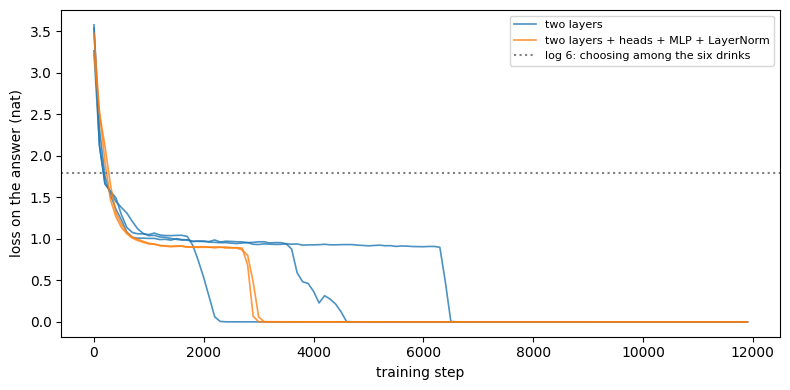

In [18]:
colors = {"two layers": "tab:blue", "two layers + heads + MLP + LayerNorm": "tab:orange"}
fig, ax = plt.subplots(figsize=(8, 4))
for (name, seed), model in trained.items():
    if name in colors:
        ax.plot(np.arange(len(model.loss_curve)) * 100, model.loss_curve, color=colors[name], alpha=0.8, linewidth=1.2, label=name if seed == 0 else None)
        below = np.flatnonzero(model.loss_curve < 0.5)
        print(f"{name}, seed {seed}: the loss goes below 0.5 " + (f"in the block of steps {below[0] * 100}-{below[0] * 100 + 99}" if len(below) else "never"))
ax.axhline(np.log(len(world.values["drink"])), color="gray", linestyle=":", label="log 6: choosing among the six drinks")
ax.set_xlabel("training step")
ax.set_ylabel("loss on the answer (nat)")
ax.legend(fontsize=8)
plt.tight_layout()

In [19]:
lengths = [2, 3, 4, 5]
tests_by_length = {n: torch.tensor(vocabulary.batch(world.recall(20 + n, 2000, items=n))) for n in lengths}
rows = {f"{name}, seed {seed}": {f"{n} people": tinylm.answer_accuracy(model, tests_by_length[n]) for n in lengths}
        for (name, seed), model in trained.items() if name in colors}
pd.DataFrame(rows).T.rename_axis("list of").round(2)

,2 people,3 people,4 people,5 people
list of,,,,
"two layers, seed 0",0.59,1.0,0.39,0.33
"two layers, seed 1",0.42,1.0,0.35,0.33
"two layers, seed 2",0.72,1.0,0.39,0.28
"two layers + heads + MLP + LayerNorm, seed 0",0.70,1.0,0.52,0.34
"two layers + heads + MLP + LayerNorm, seed 1",0.60,1.0,0.37,0.31


The complete block reaches 100% in both seeds (29,620 parameters, against 12,596 of the attention alone). The loss falls in the block of steps 2,900-2,999 in **both** seeds, inside the range of the networks with the attention alone (2,100 to 6,400 in three seeds): with two seeds we can not say that it falls earlier or more regularly. On the lists of **other lengths** nothing improves: the block is at 100% on lists of three and falls to 0.60 and 0.70 on two people, to 0.37 and 0.52 on four and to 0.31 and 0.34 on five, like the networks with the attention alone (0.42 to 0.72, 0.35 to 0.39, 0.28 to 0.33), and under the reference of the most frequent listed drink for four and five people (0.46 and 0.45 in L1.0). As in L1.0, the networks learned a procedure tied to the lengths of the training, and the ingredients of this notebook do not change that; what would change it are different *data* (a training on lists of several lengths, as in the trial of L1.0).

So **on this problem the complete block does not do better than the attention alone**, as we expected at the beginning of the section. Its ingredients were not needed to solve it. What we gained is not a higher number: it is a model that can do what the problems of Steps 2 and 3 asked for, and that trains with larger steps (Step 4), which is what is needed to make it grow.

## What we learned, and what comes next

- **The residual stream** is the vector that goes through the network and that every component reads and adds to. Because it is a sum, the scores are a sum of contributions, one for each head and for each MLP, and we can read who wrote what (Step 1). The decomposition says who wrote the answer; the ablation says who was needed to write it.
- **Several heads** let a layer read the text in several ways at once, with the same number of parameters (Step 2). On our comparison one head did not find the solution and four did; no head alone computed the equality, the result came from combining them, and some heads were redundant.
- **The MLP** computes on each position what the attention has gathered (Step 3). On the parity of the teas it wrote the alternation yes-no that the attention alone drew badly. It was useful and not necessary: a second layer of attention did the same, and for the recall of L1.0 it changed nothing.
- **The layer normalization** keeps the size of what each component reads under control. It did not improve the accuracy at the usual learning rate, and it made a training with a larger step possible (pre-LN), where the networks without it and with the post-LN did not learn (Step 4).
- **The block**, repeated, is the Transformer. In our toy it behaves like the network with the attention alone on the problem of L1.0: same accuracy, a fall of the loss in the same range of steps, the same failure on lists of other lengths. Its ingredients do not make this problem easier; they make the model able to solve the problems of Steps 2 and 3 and to be trained with larger steps (Step 5).

What changes with the real models: the same block, with tens of layers, many heads of dimension 64 to 128, MLPs that hold most of the parameters, normalization of the RMS type and a training on a very large corpus. The ingredients are those that we have built; what makes the real models different is the **scale** at which they are used. The tests of this notebook were small problems on purpose, so that we could see what each piece does: they say what an ingredient *can* do, not how much it matters in a real model.

What is missing is **how the block is used**. So far the network read a list and answered from the last position, and the causal mask was always on. In the next notebook we look at the two ways in which the block is arranged to process text: the **encoder**, in which every position can read all the others (no mask), and the **decoder**, in which a position reads only the previous ones (the causal mask), together with the **cross-attention** that connects them, and we use them on a translation task of our toy world, with the second language B.

The last section of this notebook is a **playground**: a model of this kind, trained on the documents and on the lists of our world, that you can question and that you can let continue a text one word at a time, looking at the probabilities that it assigns at each step.

## Playground: questions and autoregressive generation

> **A simple example.** Give the model the beginning `marco drinks`. It does not write a sentence: it gives, for every word of the vocabulary, the **probability** that this word comes next, and `coffee` should have most of it, because in our world `marco` drinks `coffee`. If we take `coffee` and give the model `marco drinks coffee .`, it gives again a distribution for the next word, and so on. A text is built **one word at a time**, and every word is chosen on the basis of all the previous ones, including those that the model has just written.
>
> The question of this section is: what does a language model do when we ask it something, and when we let it continue a text? The intuition is that both are the same operation, *predict the next word*, applied once (a question) or many times in a row feeding the output back as input (a continuation), and that we can **watch** the probabilities at each step.

This section can be **run on its own**: it has its own set-up cell and it does not need the cells above. We use one model with the structure of this notebook (three blocks, four heads, an MLP, pre-LN, $d = 32$, 42,261 parameters), trained to predict the next word on **both kinds of data** of L1.0: the **documents** of the world (where the facts are in the weights: `marco drinks coffee` in every document) and the **lists** to be read (`anna tea marco milk sara coffee . marco drinks milk`, where the answer is in the context). It is the two problems of L1.0 in a single model, which is also what a real language model does. The training takes about a minute and a half; the trained network is saved **outside the repository** (in `models/L1.1/`) so that it is not trained again each time. If you change the data or the settings, delete that folder.

In [20]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ipywidgets as widgets
from IPython.display import display, clear_output

from nlp import toyworld, tinylm

warnings.filterwarnings("ignore", category=FutureWarning)

CACHE = "../../models/L1.1"                                              # outside the repository: the trained network, saved only to save time
world = toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=0))
vocabulary = world.vocabulary()
SETTINGS = dict(d=32, layers=3, heads=4, mlp=4, norm="pre", max_length=32)

def load_or_train(path=f"{CACHE}/playground.pt", steps=8000, seed=0):
    if os.path.exists(path):
        model = tinylm.TinyTransformer(len(vocabulary), **SETTINGS)
        model.load_state_dict(torch.load(path))
        return model
    documents = world.documents(5, 20000, n_people=2, n_facts=3)
    lists = world.recall(6, 20000, items=3)
    data = torch.tensor(vocabulary.batch(documents + lists))
    model = tinylm.fit_lm(data, seed=seed, steps=steps, **SETTINGS)
    os.makedirs(CACHE, exist_ok=True)
    torch.save(model.state_dict(), path)
    return model

model = load_or_train()
print(f"{model.n_parameters():,} parameters")

42,261 parameters


### Asking a question

A question is a text that stops at the point where we want the answer: the model returns the distribution of the next word, and we draw the most probable ones. We try three: a **list to be read** (the answer is in the text: `marco` has `milk` *in this list*), a **fact of the world** (the answer is in the weights: `marco` drinks `coffee` in every document of our world) and a **pronoun** (`she` is `marta`, who lives in `turin`).

'<s> anna tea marco milk sara coffee . marco drinks': `milk` 0.999, then `farmer` 0.000
'<s> marco drinks': `coffee` 1.000, then `juice` 0.000
'<s> marta likes brown . she lives in': `turin` 1.000, then `bari` 0.000
{'marco': ('coffee', 'naples'), 'marta': ('tea', 'turin')}


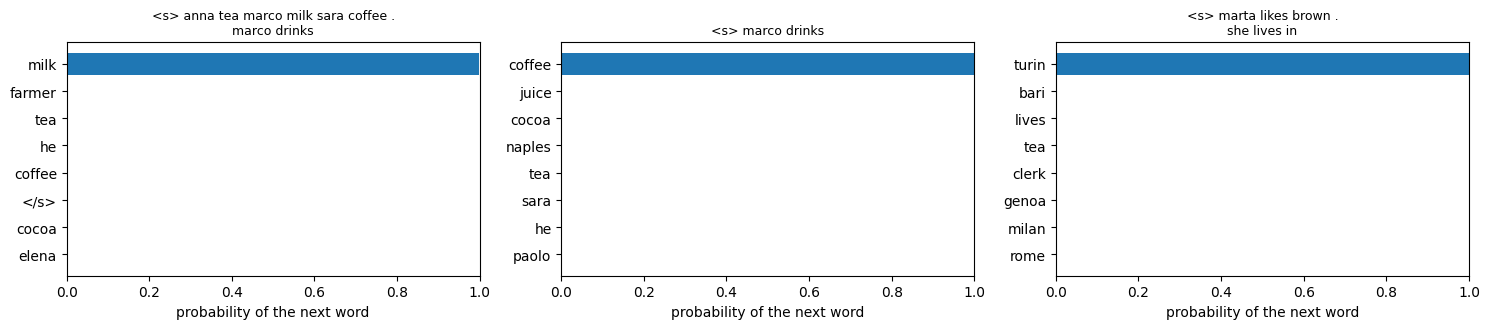

In [21]:
def next_word_chart(ax, probabilities, k=8, chosen=None):
    top = probabilities.topk(k)
    words = vocabulary.decode(top.indices.tolist())
    colors = ["tab:orange" if i == chosen else "tab:blue" for i in top.indices.tolist()]
    ax.barh(range(k), top.values.numpy(), color=colors)
    ax.set_yticks(range(k))
    ax.set_yticklabels(words)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("probability of the next word")

def ask(prompts):
    fig, axes = plt.subplots(1, len(prompts), figsize=(5 * len(prompts), 3.4))
    for ax, prompt in zip(np.atleast_1d(axes), prompts):
        probabilities = tinylm.next_word_probabilities(model, vocabulary.encode(prompt.split()))
        next_word_chart(ax, probabilities)
        ax.set_title(prompt.replace(" . ", " .\n"), fontsize=9)
        top = probabilities.topk(2)
        print(f"{prompt!r}: `{vocabulary.words[top.indices[0]]}` {top.values[0]:.3f}, then `{vocabulary.words[top.indices[1]]}` {top.values[1]:.3f}")
    plt.tight_layout()

ask(["<s> anna tea marco milk sara coffee . marco drinks",
     "<s> marco drinks",
     "<s> marta likes brown . she lives in"])
print({row["person"]: (row["drink"], row["city"]) for row in world.table() if row["person"] in ("marco", "marta")})

The three questions are answered with a probability close to 1: `milk` 0.999 for the list, `coffee` 1.000 for the fact of the world, `turin` 1.000 for the pronoun. The model uses two different sources: in the first case the same name, `marco`, has another drink in other lists, so the answer must be **read** in the text; in the second the answer must be **known**, because the text does not say it; in the third it needs both, the context to understand that `she` is `marta` and the weights to know where `marta` lives. Nobody told the model which source to use: it learned it from the data. Note also how concentrated the distributions are: in our world these facts are certain, and the other words have a probability near 0. In a real model the next word of a free text is rarely so certain.

### Continuing a text

To continue a text the model is used in a loop: it gives the distribution of the next word, **one word is chosen** and appended to the text, and the longer text is given back to the model. The choice can be the most probable word (*greedy*, temperature 0) or a **draw** from the distribution (*sampling*; the temperature, as in L0.3, flattens the distribution when it is above 1 and sharpens it when it is below). The figure shows the first steps from the beginning `<s> marco drinks`: for each step the distribution that the model gave (in orange the word that was chosen) and the text that is being written.

step 1: chosen `coffee`; the most probable: `coffee` 1.00, `juice` 0.00, `cocoa` 0.00
step 2: chosen `.`; the most probable: `.` 1.00, `in` 0.00, `red` 0.00
step 3: chosen `he`; the most probable: `he` 0.69, `marco` 0.30, `mario` 0.00
step 4: chosen `likes`; the most probable: `likes` 0.34, `is` 0.33, `lives` 0.33
step 5: chosen `brown`; the most probable: `brown` 1.00, `red` 0.00, `pink` 0.00
step 6: chosen `.`; the most probable: `.` 1.00, `genoa` 0.00, `coffee` 0.00
step 7: chosen `he`; the most probable: `he` 0.69, `marco` 0.31, `she` 0.00
step 8: chosen `lives`; the most probable: `lives` 0.51, `is` 0.49, `likes` 0.00
greedy:   <s> marco drinks coffee . he likes brown . he lives


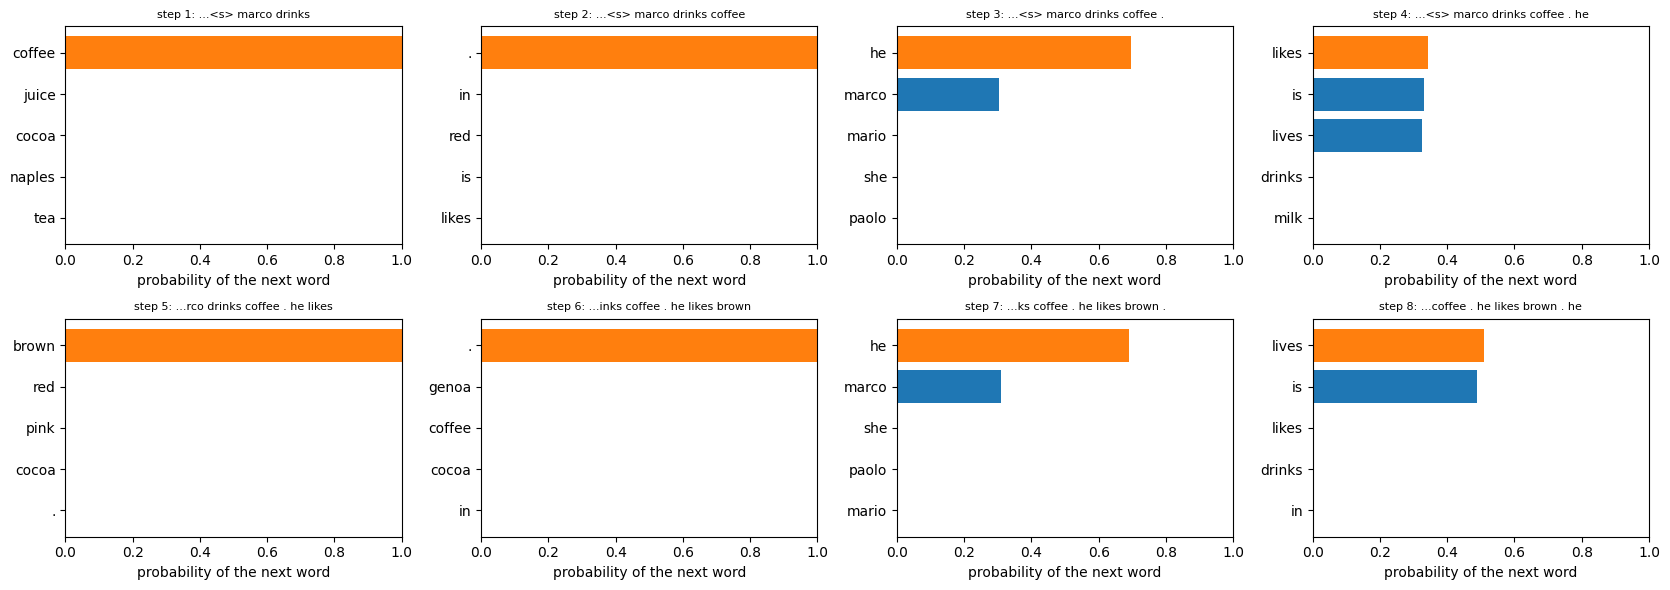

In [22]:
def show_generation(prompt, steps=8, temperature=0.0, seed=0, columns=4):
    ids, distributions = tinylm.generate(model, vocabulary.encode(prompt.split()), steps, temperature=temperature, seed=seed,
                                         stop=vocabulary.index["</s>"])
    start = len(ids) - len(distributions)
    rows = int(np.ceil(len(distributions) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.2 * columns, 3.0 * rows), squeeze=False)
    for t, probabilities in enumerate(distributions):
        text = " ".join(vocabulary.decode(ids[:start + t]))
        next_word_chart(axes[t // columns, t % columns], probabilities, k=5, chosen=ids[start + t])
        axes[t // columns, t % columns].set_title(f"step {t + 1}: ...{text[-28:]}", fontsize=8)
    for ax in axes.flat[len(distributions):]:
        ax.axis("off")
    plt.tight_layout()
    for t, probabilities in enumerate(distributions):
        top = probabilities.topk(3)
        print(f"step {t + 1}: chosen `{vocabulary.words[ids[start + t]]}`; the most probable: " +
              ", ".join(f"`{vocabulary.words[i]}` {p:.2f}" for p, i in zip(top.values.tolist(), top.indices.tolist())))
    return " ".join(vocabulary.decode(ids))

print("greedy:  ", show_generation("<s> marco drinks", steps=8, temperature=0.0))

The distributions are sharp where the world has a fact and spread where the text is free. The facts: `coffee` at the first step (1.00), `brown` at the fifth (1.00). The free choices are where the model shows what it learned about the **data**. At step 3, after `marco drinks coffee .`, it gives 0.69 to `he` and 0.30 to `marco`: in the documents of our generator a pronoun replaces the name in 70% of the cases in which the subject is the same as in the previous sentence, and the model has learned that frequency (at step 7 it gives 0.69 and 0.31 again). At step 4 the three relations that are left, `likes`, `is` and `lives`, get 0.34, 0.33 and 0.33: a person has three facts chosen among four relations, so after `drinks` the other three are equally likely (at step 8, with `drinks` and `likes` already said, `lives` and `is` get 0.51 and 0.49). **The probabilities of a language model are the frequencies of the data it was trained on**, here exactly those of our generator.

The *greedy* choice takes the most probable word at each step, and so the text `marco drinks coffee . he likes brown . he lives` is a sequence of choices of which some are ties (0.34 against 0.33). It is the most probable word at each step, not the most probable text, and it is always the same: to get different texts we need to draw from the distribution.

In [23]:
for seed in range(3):
    ids, _ = tinylm.generate(model, vocabulary.encode("<s> marco drinks coffee .".split()), 24, temperature=1.0, seed=seed, stop=vocabulary.index["</s>"])
    print(f"sampling, seed {seed}:", " ".join(vocabulary.decode(ids)))

sampling, seed 0: <s> marco drinks coffee . he is a nurse . marco lives in naples . marta drinks tea . she is a mechanic . she likes brown . </s>
sampling, seed 1: <s> marco drinks coffee . he lives in naples . he likes brown . anna likes red . she drinks cocoa . she is a farmer . </s>
sampling, seed 2: <s> marco drinks coffee . he is a nurse . marco likes brown . mario likes yellow . he is a clerk . he drinks water . </s>


With the temperature at 1 the words are drawn from the distribution, and the three texts are different: in each of them the free choices change (which person speaks, which relation, a name or a pronoun) while the facts, when they appear, are those of the table of the world. The next cell measures it on many texts. Try a temperature of 0 (the most probable word) and of 2 (a flatter distribution) in the panel at the end.

In [24]:
RELATIONS = {"drinks": "drink", "is": "job", "lives": "city", "likes": "color"}

def check_document(words):
    # the sentences of a generated document: (sentences, well formed, true in the world); `he`/`she` refer to the previous subject
    sentences, well_formed, true, subject, sentence = 0, 0, 0, None, []
    for word in words:
        if word != ".":
            sentence.append(word)
            continue
        sentences += 1
        if len(sentence) >= 3 and sentence[1] in RELATIONS:
            who = sentence[0] if sentence[0] in world.people else subject if sentence[0] in ("he", "she") else None
            if who is not None and sentence[-1] in world.values[RELATIONS[sentence[1]]]:
                well_formed += 1
                subject = who
                true += world.attributes[who][RELATIONS[sentence[1]]] == sentence[-1]
        sentence = []
    return sentences, well_formed, true

def check_list(words):
    # a generated list `n1 d1 n2 d2 ... . n drinks answer`: has it the question, and does the answer agree with the list?
    memory, i = {}, 0
    while i + 1 < len(words) and words[i] in world.people and words[i + 1] in world.values["drink"]:
        memory.setdefault(words[i], set()).add(words[i + 1])
        i += 2
    asked = words[i:]
    has_question = len(asked) == 4 and asked[0] == "." and asked[1] in memory and asked[2] == "drinks"
    return has_question, has_question and asked[3] in memory[asked[1]]

documents = lists = 0
sentences = np.zeros(3)
questions = answers = 0
for seed in range(100):
    ids, _ = tinylm.generate(model, [vocabulary.index["<s>"]], 40, temperature=1.0, seed=seed, stop=vocabulary.index["</s>"])
    words = [w for w in vocabulary.decode(ids[1:]) if w != "</s>"]
    if len(words) > 1 and words[0] in world.people and words[1] in world.values["drink"]:       # a list to be read
        lists += 1
        has_question, correct = check_list(words)
        questions += has_question
        answers += correct
    else:                                                                                      # a document
        documents += 1
        sentences += check_document(words)
print(f"100 texts generated by sampling from `<s>`: {documents} documents and {lists} lists")
print(f"documents: {sentences[0]:.0f} sentences, {sentences[1] / sentences[0]:.1%} well formed, {sentences[2] / sentences[1]:.1%} of the well formed ones say something true in the world")
print(f"lists: {questions} have a question at the end, and in {answers} of them the answer agrees with the list")

100 texts generated by sampling from `<s>`: 47 documents and 53 lists
documents: 283 sentences, 99.6% well formed, 99.6% of the well formed ones say something true in the world
lists: 52 have a question at the end, and in 51 of them the answer agrees with the list


From `<s>` the model produces both kinds of text, 47 documents and 53 lists in 100 draws, close to the half-and-half mixture of the training data: the first word alone does not say which kind it will be, and the model has learned that both are possible. In the documents, 99.6% of the 283 sentences are well formed and 99.6% of those say something true in the world (the function counts as true a sentence that agrees with the table, resolving `he` and `she` as the previous subject). In the lists, 52 out of 53 have a question at the end and in 51 of the 52 the answer agrees with the list. So the model has learned, from the next-word prediction alone, **both the facts of the world and the procedure to read a list**; the measure says nothing about what is *not* in our world, which the model has never seen.

The model was trained on lists of **three** people, and as in L1.0 (Step 6) we can ask what it does on lists of other lengths. We give it 1,000 new lists for each length and we measure how often the word that it gives after `drinks` is the right one.

In [25]:
rows = {f"{n} people": tinylm.answer_accuracy(model, torch.tensor(vocabulary.batch(world.recall(20 + n, 1000, items=n)))) for n in (2, 3, 4, 5)}
pd.Series(rows, name="accuracy of the answer").to_frame().T.round(2)

,2 people,3 people,4 people,5 people
accuracy of the answer,0.38,1.0,0.3,0.22


On lists of three people the answer is right 1.00 of the times, and on lists of two, four and five people 0.38, 0.30 and 0.22: the same limit that we found in L1.0 (Step 6) and that the block of Step 5 did not remove. The model learned a procedure for the lists that it saw. In the panel below, try a list of two or four people and look at what the model answers.

### Try it yourself

The panel below lets you write a beginning (words separated by spaces, starting with `<s>`; the words must be in the vocabulary of the world: the names, the drinks, the jobs, the cities, the colours and the words `drinks`, `is`, `a`, `lives`, `in`, `likes`, `he`, `she`, `.`), choose the temperature, the number of words and the seed, and then **move through the steps** with the slider or with the *play* button, looking at the text that composes and at the distribution that produced each word. Run the cells of this section from the set-up cell on; there is no need to run the rest of the notebook.

In [26]:
prompt_box = widgets.Text(value="<s> marco drinks coffee .", description="beginning", layout=widgets.Layout(width="70%"))
temperature_box = widgets.FloatSlider(value=1.0, min=0.0, max=2.0, step=0.1, description="temperature")
steps_box = widgets.IntSlider(value=12, min=1, max=30, description="words")
seed_box = widgets.IntText(value=0, description="seed", layout=widgets.Layout(width="150px"))
run_button = widgets.Button(description="generate", button_style="primary")
step_slider = widgets.IntSlider(value=0, min=0, max=0, description="step", continuous_update=True)
play = widgets.Play(value=0, min=0, max=0, step=1, interval=700)
widgets.jslink((play, "value"), (step_slider, "value"))
output = widgets.Output()
state = {}

def draw(_=None):
    with output:
        clear_output(wait=True)
        if not state:
            return
        ids, distributions, start = state["ids"], state["distributions"], state["start"]
        t = step_slider.value
        print("text so far: ", " ".join(vocabulary.decode(ids[:start + t])), "|", " ".join(vocabulary.decode(ids[start + t:])) if t < len(distributions) else "")
        if t == 0:
            print("(move the slider to see the words appear)")
            return
        fig, ax = plt.subplots(figsize=(5.5, 3.2))
        next_word_chart(ax, distributions[t - 1], k=8, chosen=ids[start + t - 1])
        ax.set_title(f"step {t}: the word `{vocabulary.words[ids[start + t - 1]]}` was chosen (orange)", fontsize=9)
        plt.tight_layout()
        plt.show()

def generate_clicked(_=None):
    words = prompt_box.value.split()
    unknown = [w for w in words if w not in vocabulary.index]
    with output:
        if unknown or not words:
            clear_output(wait=True)
            print("words that are not in the vocabulary:", unknown if unknown else "(the beginning is empty)")
            return
    ids, distributions = tinylm.generate(model, vocabulary.encode(words), steps_box.value, temperature=temperature_box.value,
                                         seed=seed_box.value, stop=vocabulary.index["</s>"])
    state.update(ids=ids, distributions=distributions, start=len(words))
    step_slider.max = play.max = len(distributions)
    step_slider.value = play.value = 0
    draw()

run_button.on_click(generate_clicked)
step_slider.observe(draw, names="value")
display(widgets.VBox([prompt_box, widgets.HBox([temperature_box, steps_box, seed_box, run_button]), widgets.HBox([play, step_slider]), output]))
generate_clicked()

Some things to try in the panel (we have tested only those with a measure above): the beginning `<s> marco is a` (the job of `marco`), a list with two or four people (where we know that the model fails), a temperature of 0 and of 2, the same beginning with different seeds, a beginning with a word that is not in the vocabulary (the panel says it).

**What changes with the real models.** The loop is exactly the same: a distribution over the next token, a choice, the token appended to the text. What changes is the size. The vocabulary has tens of thousands of tokens (the subwords of L0.1), the distributions are rarely as concentrated as here, and the choice is often restricted to the most probable tokens to avoid improbable ones. Some services return the probabilities of the most likely tokens at each step, the same objects that we have drawn in the figures. And what we called a *question* is only a text that stops where we want the answer: a model that has been trained further to follow instructions (L2.1) is used in the same way, with a text that has the form of a request.